# Install & import libraries

In [10]:
!pip install pandas numpy scikit-learn gensim matplotlib seaborn

In [11]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import gensim.downloader as api

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load training set

In [12]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

train_df = train_df[['label', 'text']].dropna()

X_train = train_df['text'].astype(str)
y_train = train_df['label']

X_test = test_df['text'].astype(str)
y_test = test_df['label']


print(train_df.head())
print(train_df['label'].value_counts())

   label                                               text
0      0                         Going on nothing great.bye
1      0                      I wont. So wat's wit the guys
2      0            Ok k..sry i knw 2 siva..tats y i askd..
3      0  Where are you ? What do you do ? How can you s...
4      0       Have you not finished work yet or something?
label
0    3859
1     598
Name: count, dtype: int64


# Pretrained Word2Vec and GloVe vectors

Using pretrained embeddings for simplicity

In [13]:
word2vec_model = api.load("word2vec-google-news-300")
glove_model = api.load("glove-wiki-gigaword-100")

In [14]:
def average_word_vectors(text, model):
    words = text.split()

    vectors = [ model[word] for word in words if word in model ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

## Word2Vec into vectors

In [15]:
X_train_w2v = np.array([ average_word_vectors(text, word2vec_model) for text in X_train ])

X_test_w2v = np.array([ average_word_vectors(text, word2vec_model) for text in X_test ])

## GloVe into vectors

In [16]:
X_train_glove = np.array([ average_word_vectors(text, glove_model) for text in X_train ])

X_test_glove = np.array([ average_word_vectors(text, glove_model) for text in X_test ])

# KNN with Word2Vec

## Training

In [17]:
knn = KNeighborsClassifier()

param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['cosine', 'euclidean']
}

grid_w2v = GridSearchCV(
    knn,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_w2v.fit(X_train_w2v, y_train)

print("Best Word2Vec parameters:")
print(grid_w2v.best_params_)

Best Word2Vec parameters:
{'metric': 'cosine', 'n_neighbors': 3, 'weights': 'distance'}


## Evaluation

In [18]:
y_pred_w2v = grid_w2v.predict(X_test_w2v)

print("Word2Vec + KNN Results")

print("Accuracy:", accuracy_score(y_test, y_pred_w2v))

print("Precision:", precision_score(y_test, y_pred_w2v, average='macro', zero_division=0))

print("Recall:", recall_score(y_test, y_pred_w2v, average='macro', zero_division=0))

print("F1 Score:", f1_score(y_test, y_pred_w2v, average='macro', zero_division=0))

print(classification_report(y_test, y_pred_w2v))

Word2Vec + KNN Results
Accuracy: 0.9560538116591928
Precision: 0.9025318358200798
Recall: 0.9093612350104909
F1 Score: 0.9059037698771505
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       966
           1       0.83      0.85      0.84       149

    accuracy                           0.96      1115
   macro avg       0.90      0.91      0.91      1115
weighted avg       0.96      0.96      0.96      1115



# KNN with GloVe

## Training

In [19]:
grid_glove = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_glove.fit(X_train_glove, y_train)

print("Best GloVe parameters:")
print(grid_glove.best_params_)

Best GloVe parameters:
{'metric': 'cosine', 'n_neighbors': 11, 'weights': 'distance'}


## Evaluation

In [20]:
y_pred_glove = grid_glove.predict(X_test_glove)

print("GloVe + KNN Results")

print("Accuracy:", accuracy_score(y_test, y_pred_glove))

print("Precision:", precision_score(y_test, y_pred_glove, average='macro', zero_division=0))

print("Recall:", recall_score(y_test, y_pred_glove, average='macro', zero_division=0))

print("F1 Score:", f1_score(y_test, y_pred_glove, average='macro', zero_division=0))

print(classification_report(y_test, y_pred_glove))

GloVe + KNN Results
Accuracy: 0.947085201793722
Precision: 0.8849740932642487
Recall: 0.8871566134478303
F1 Score: 0.8860607341232384
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       966
           1       0.80      0.81      0.80       149

    accuracy                           0.95      1115
   macro avg       0.88      0.89      0.89      1115
weighted avg       0.95      0.95      0.95      1115



# TF-IDF + KNN baseline

## Training

In [21]:
tfidf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer( max_features=10000, ngram_range=(1, 2) )),
    ('knn', KNeighborsClassifier())
])

tfidf_params = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['cosine', 'euclidean']
}

grid_tfidf = GridSearchCV(
    tfidf_pipeline,
    tfidf_params,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid_tfidf.fit(X_train, y_train)

print("Best TF-IDF parameters:")
print(grid_tfidf.best_params_)

Best TF-IDF parameters:
{'knn__metric': 'cosine', 'knn__n_neighbors': 5, 'knn__weights': 'distance'}


## Evaluate

In [24]:
y_pred_tfidf = grid_tfidf.predict(X_test)

print("TF-IDF + KNN Results")

print("Accuracy:", accuracy_score(y_test, y_pred_tfidf))

print("Precision:", precision_score(y_test, y_pred_tfidf, average='macro', zero_division=0))

print("Recall:", recall_score(y_test, y_pred_tfidf, average='macro', zero_division=0))

print("F1 Score:", f1_score(y_test, y_pred_tfidf, average='macro', zero_division=0))

print(classification_report(y_test, y_pred_tfidf))

TF-IDF + KNN Results
Accuracy: 0.9766816143497757
Precision: 0.9767088070191989
Recall: 0.9212659969152528
F1 Score: 0.9465775740063687
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.85      0.91       149

    accuracy                           0.98      1115
   macro avg       0.98      0.92      0.95      1115
weighted avg       0.98      0.98      0.98      1115



# Comparison between the three

In [25]:
results = pd.DataFrame({
    'Model': [
        'Word2Vec + KNN',
        'GloVe + KNN',
        'TF-IDF + KNN'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_w2v),
        accuracy_score(y_test, y_pred_glove),
        accuracy_score(y_test, y_pred_tfidf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_w2v, average='macro', zero_division=0),
        precision_score(y_test, y_pred_glove, average='macro', zero_division=0),
        precision_score(y_test, y_pred_tfidf, average='macro', zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred_w2v, average='macro', zero_division=0),
        recall_score(y_test, y_pred_glove, average='macro', zero_division=0),
        recall_score(y_test, y_pred_tfidf, average='macro', zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_w2v, average='macro', zero_division=0),
        f1_score(y_test, y_pred_glove, average='macro', zero_division=0),
        f1_score(y_test, y_pred_tfidf, average='macro', zero_division=0)
    ]
})

print(results)

            Model  Accuracy  Precision    Recall  F1 Score
0  Word2Vec + KNN  0.956054   0.902532  0.909361  0.905904
1     GloVe + KNN  0.947085   0.884974  0.887157  0.886061
2    TF-IDF + KNN  0.976682   0.976709  0.921266  0.946578


# Visualization

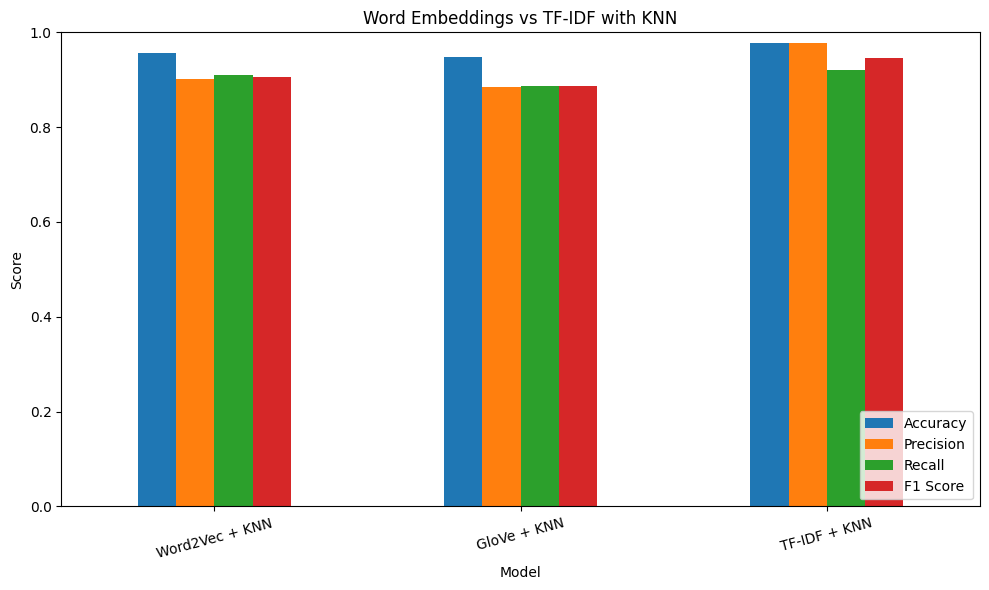

In [26]:
results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Word Embeddings vs TF-IDF with KNN')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Confusion matrices

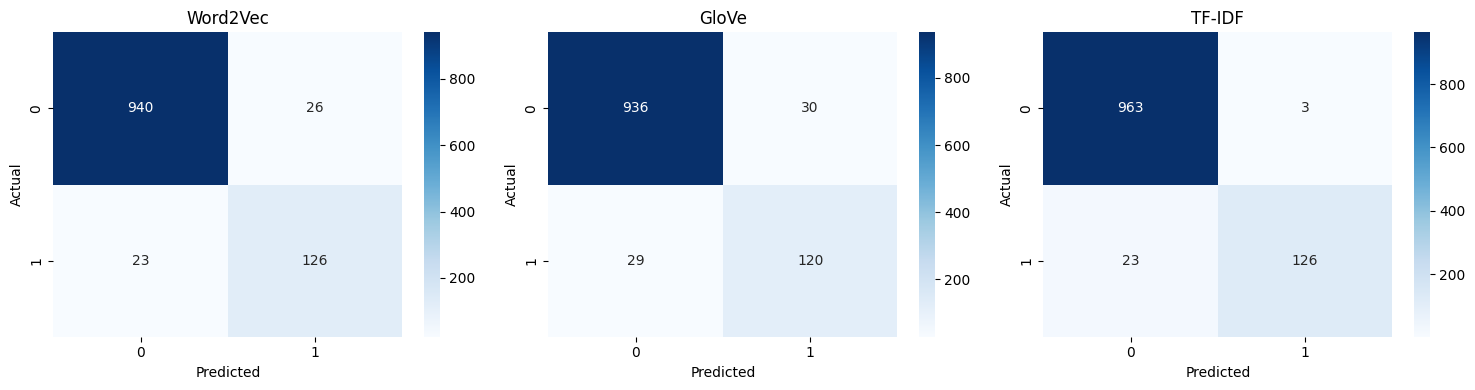

In [27]:
predictions = {
    'Word2Vec': y_pred_w2v,
    'GloVe': y_pred_glove,
    'TF-IDF': y_pred_tfidf
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions_model) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, predictions_model)
    sns.heatmap(cm, annot=True,fmt='d', cmap='Blues', ax=ax)

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()